In [1]:
# Compare Oracle's reported operating cash flow and capital expenditure
import pandas as pd

oracle_cash_flow = pd.DataFrame({
    "Measure": [
        "Operating Cash Flow",
        "Capital Expenditure",
        "Free Cash Flow"
    ],
    "USD Millions": [
        23103,
        28499,
        23103 - 28499
    ]
})

oracle_cash_flow

,Measure,USD Millions
0,Operating Cash Flow,23103
1,Capital Expenditure,28499
2,Free Cash Flow,-5396


In [2]:
# Measure capital spending relative to operating cash flow
operating_cash_flow = 23103
capital_expenditure = 28499

capex_ratio = capital_expenditure / operating_cash_flow

print(capex_ratio * 100)

123.3562740769597


In [3]:
# Calculate capital spending not covered by operating cash flow
funding_gap = capital_expenditure - operating_cash_flow

print(funding_gap)

5396


In [4]:
# Compare Oracle's cash generation and capital spending across recent quarters
cash_history = pd.DataFrame({
    "Quarter": ["FY26 Q1", "FY26 Q2", "FY26 Q3", "FY26 Q4", "FY27 Q1"],
    "Operating Cash Flow": [8140, 2066, 7151, 14620, 23103],
    "Capital Expenditure": [8502, 12033, 18635, 16493, 28499]
})

cash_history["Free Cash Flow"] = (
    cash_history["Operating Cash Flow"]
    - cash_history["Capital Expenditure"]
)

cash_history

,Quarter,Operating Cash Flow,Capital Expenditure,Free Cash Flow
0,FY26 Q1,8140,8502,-362
1,FY26 Q2,2066,12033,-9967
2,FY26 Q3,7151,18635,-11484
3,FY26 Q4,14620,16493,-1873
4,FY27 Q1,23103,28499,-5396


In [5]:
# Calculate the latest 12 months of cash flow to establish an annual baseline
latest_four_quarters = cash_history.tail(4)

annual_operating_cash_flow = latest_four_quarters["Operating Cash Flow"].sum()
annual_capex = latest_four_quarters["Capital Expenditure"].sum()

annual_free_cash_flow = annual_operating_cash_flow - annual_capex

print("TTM operating cash flow:", annual_operating_cash_flow)
print("TTM capital expenditure:", annual_capex)
print("TTM free cash flow:", annual_free_cash_flow)

TTM operating cash flow: 46940
TTM capital expenditure: 75660
TTM free cash flow: -28720


In [6]:
# Explore when growing operating cash flow could cover constant capital spending
forecast_years = [1, 2, 3, 4, 5]

forecast_ocf = [
    annual_operating_cash_flow * (1.20 ** year)
    for year in forecast_years
]

forecast = pd.DataFrame({
    "Year Ahead": forecast_years,
    "Operating Cash Flow": forecast_ocf,
    "Capital Expenditure": annual_capex
})

forecast["Free Cash Flow"] = (
    forecast["Operating Cash Flow"]
    - forecast["Capital Expenditure"]
)

forecast.round(2)

,Year Ahead,Operating Cash Flow,Capital Expenditure,Free Cash Flow
0,1,56328.00,75660,-19332.00
1,2,67593.60,75660,-8066.40
2,3,81112.32,75660,5452.32
3,4,97334.78,75660,21674.78
4,5,116801.74,75660,41141.74


In [7]:
# Track the cumulative cash surplus or shortfall across the forecast years
forecast["Cumulative Free Cash Flow"] = forecast["Free Cash Flow"].cumsum()

forecast.round(2)

,Year Ahead,Operating Cash Flow,Capital Expenditure,Free Cash Flow,Cumulative Free Cash Flow
0,1,56328.00,75660,-19332.00,-19332.00
1,2,67593.60,75660,-8066.40,-27398.40
2,3,81112.32,75660,5452.32,-21946.08
3,4,97334.78,75660,21674.78,-271.30
4,5,116801.74,75660,41141.74,40870.44


In [8]:
# Test how operating cash-flow growth affects annual free cash flow
scenario_cash_flows = pd.DataFrame({
    "Year Ahead": forecast_years,
    "10% Growth": [
        annual_operating_cash_flow * (1.10 ** year) - annual_capex
        for year in forecast_years
    ],
    "20% Growth": [
        annual_operating_cash_flow * (1.20 ** year) - annual_capex
        for year in forecast_years
    ],
    "30% Growth": [
        annual_operating_cash_flow * (1.30 ** year) - annual_capex
        for year in forecast_years
    ]
})

scenario_cash_flows.round(2)

,Year Ahead,10% Growth,20% Growth,30% Growth
0,1,-24026.00,-19332.00,-14638.00
1,2,-18862.60,-8066.40,3668.60
2,3,-13182.86,5452.32,27467.18
3,4,-6935.15,21674.78,58405.33
4,5,-62.66,41141.74,98624.93


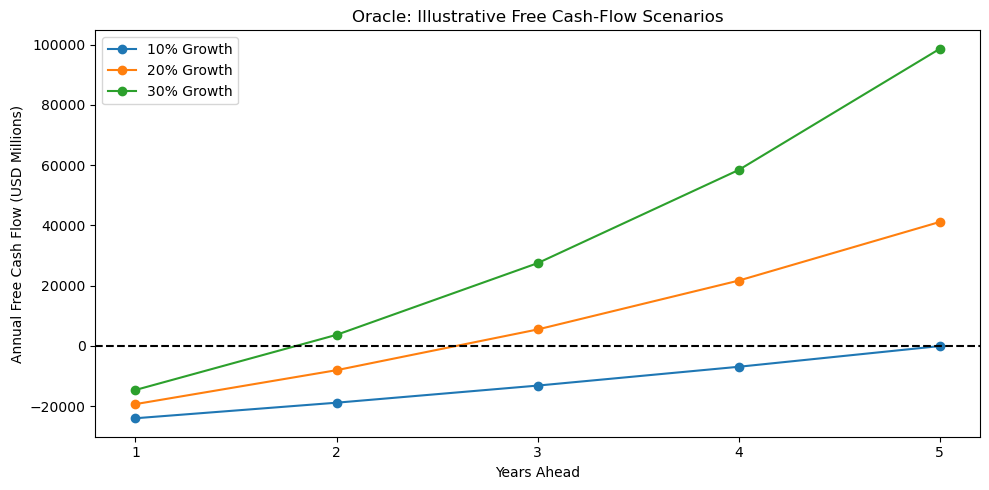

In [9]:
# Show how different growth assumptions affect free cash-flow recovery
import matplotlib.pyplot as plt

scenario_cash_flows.plot(
    x="Year Ahead",
    figsize=(10, 5),
    marker="o"
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Oracle: Illustrative Free Cash-Flow Scenarios")
plt.xlabel("Years Ahead")
plt.ylabel("Annual Free Cash Flow (USD Millions)")
plt.xticks(forecast_years)
plt.tight_layout()

plt.show()

In [10]:
# Test cash-flow recovery when capital spending also increases
capex_growth = 0.10

forecast["Growing Capital Expenditure"] = [
    annual_capex * ((1 + capex_growth) ** year)
    for year in forecast_years
]

forecast["Free Cash Flow With Growing Capex"] = (
    forecast["Operating Cash Flow"]
    - forecast["Growing Capital Expenditure"]
)

forecast.round(2)

,Year Ahead,Operating Cash Flow,Capital Expenditure,Free Cash Flow,Cumulative Free Cash Flow,Growing Capital Expenditure,Free Cash Flow With Growing Capex
0,1,56328.00,75660,-19332.00,-19332.00,83226.00,-26898.00
1,2,67593.60,75660,-8066.40,-27398.40,91548.60,-23955.00
2,3,81112.32,75660,5452.32,-21946.08,100703.46,-19591.14
3,4,97334.78,75660,21674.78,-271.30,110773.81,-13439.02
4,5,116801.74,75660,41141.74,40870.44,121851.19,-5049.45


In [11]:
# Measure the cumulative cash shortfall when capital spending grows
forecast["Cumulative FCF With Growing Capex"] = (
    forecast["Free Cash Flow With Growing Capex"].cumsum()
)

print(forecast["Cumulative FCF With Growing Capex"].round(2))

0   -26898.00
1   -50853.00
2   -70444.14
3   -83883.16
4   -88932.61
Name: Cumulative FCF With Growing Capex, dtype: float64


In [12]:
# Compare annual free cash flow under constant and growing capital spending
capex_comparison = pd.DataFrame({
    "Year Ahead": forecast_years,
    "Constant Capex FCF": forecast["Free Cash Flow"],
    "Growing Capex FCF": forecast["Free Cash Flow With Growing Capex"]
})

capex_comparison.round(2)

,Year Ahead,Constant Capex FCF,Growing Capex FCF
0,1,-19332.00,-26898.00
1,2,-8066.40,-23955.00
2,3,5452.32,-19591.14
3,4,21674.78,-13439.02
4,5,41141.74,-5049.45


In [13]:
# Separate identified customer prepayments from latest-quarter operating cash flow
reported_quarter_ocf = 23103
customer_prepayments = 11363

ocf_excluding_prepayments = reported_quarter_ocf - customer_prepayments

cash_quality = pd.DataFrame({
    "Measure": [
        "Reported operating cash flow",
        "Identified customer prepayments",
        "Operating cash flow excluding those prepayments"
    ],
    "USD Millions": [
        reported_quarter_ocf,
        customer_prepayments,
        ocf_excluding_prepayments
    ]
})

cash_quality

,Measure,USD Millions
0,Reported operating cash flow,23103
1,Identified customer prepayments,11363
2,Operating cash flow excluding those prepayments,11740


In [14]:
# Calculate quarterly operating profit after an assumed tax charge
quarterly_operating_profit = 6728
assumed_tax_rate = 0.20

quarterly_nopat = quarterly_operating_profit * (1 - assumed_tax_rate)

print(quarterly_nopat)

5382.400000000001


In [15]:
# Display quarterly after-tax operating profit rounded to two decimal places
print(round(quarterly_nopat, 2))

5382.4


In [16]:
# Add back non-cash depreciation and amortisation to quarterly NOPAT
quarterly_depreciation = 3156
quarterly_amortisation = 202

quarterly_da = quarterly_depreciation + quarterly_amortisation

quarterly_nopat_plus_da = quarterly_nopat + quarterly_da

print(quarterly_nopat_plus_da)

8740.400000000001


In [17]:
# Subtract capital investment to estimate cash flow before working-capital changes
quarterly_capex = 28499

cash_flow_before_working_capital = quarterly_nopat_plus_da - quarterly_capex

print(round(cash_flow_before_working_capital, 2))

-19758.6


In [18]:
# Estimate quarterly working-capital investment excluding taxes and deferred revenues
receivables_cash_outflow = 1009
prepaid_assets_cash_inflow = 114
other_operating_liabilities_cash_outflow = 1076

working_capital_investment = (
    receivables_cash_outflow
    - prepaid_assets_cash_inflow
    + other_operating_liabilities_cash_outflow
)

quarterly_fcff_proxy = (
    cash_flow_before_working_capital - working_capital_investment
)

print("Working-capital investment:", working_capital_investment)
print("Quarterly FCFF proxy:", round(quarterly_fcff_proxy, 2))

Working-capital investment: 1971
Quarterly FCFF proxy: -21729.6


In [19]:
# Establish an annual revenue and operating-profit scenario for valuation
annual_revenue = 90000

assumed_operating_margin = 6728 / 19345

forecast_operating_profit = annual_revenue * assumed_operating_margin

forecast_nopat = forecast_operating_profit * (1 - assumed_tax_rate)

print("Assumed operating margin (%):", round(assumed_operating_margin * 100, 2))
print("Forecast annual operating profit:", round(forecast_operating_profit, 2))
print("Forecast annual NOPAT:", round(forecast_nopat, 2))

Assumed operating margin (%): 34.78
Forecast annual operating profit: 31301.11
Forecast annual NOPAT: 25040.89


In [20]:
# Forecast annual revenue with growth slowing over five years
revenue_growth_rates = [0.25, 0.20, 0.15, 0.10, 0.06]

projected_revenues = []
revenue = annual_revenue

for growth_rate in revenue_growth_rates:
    revenue = revenue * (1 + growth_rate)
    projected_revenues.append(revenue)

valuation_forecast = pd.DataFrame({
    "Year Ahead": [1, 2, 3, 4, 5],
    "Revenue Growth (%)": [25, 20, 15, 10, 6],
    "Revenue": projected_revenues
})

valuation_forecast

,Year Ahead,Revenue Growth (%),Revenue
0,1,25,112500.0
1,2,20,135000.0
2,3,15,155250.0
3,4,10,170775.0
4,5,6,181021.5


In [21]:
# Estimate annual operating profit and after-tax operating profit
valuation_forecast["Operating Profit"] = (
    valuation_forecast["Revenue"] * assumed_operating_margin
)

valuation_forecast["NOPAT"] = (
    valuation_forecast["Operating Profit"] * (1 - assumed_tax_rate)
)

valuation_forecast.round(2)

,Year Ahead,Revenue Growth (%),Revenue,Operating Profit,NOPAT
0,1,25,112500.0,39126.39,31301.11
1,2,20,135000.0,46951.67,37561.33
2,3,15,155250.0,53994.42,43195.53
3,4,10,170775.0,59393.86,47515.09
4,5,6,181021.5,62957.49,50365.99


In [22]:
# Estimate reinvestment required to support projected revenue growth
sales_to_capital = 0.50

previous_revenue = valuation_forecast["Revenue"].shift(1)
previous_revenue.iloc[0] = annual_revenue

valuation_forecast["Revenue Increase"] = (
    valuation_forecast["Revenue"] - previous_revenue
)

valuation_forecast["Net Reinvestment"] = (
    valuation_forecast["Revenue Increase"] / sales_to_capital
)

valuation_forecast["FCFF"] = (
    valuation_forecast["NOPAT"] - valuation_forecast["Net Reinvestment"]
)

valuation_forecast.round(2)

,Year Ahead,Revenue Growth (%),Revenue,Operating Profit,NOPAT,Revenue Increase,Net Reinvestment,FCFF
0,1,25,112500.0,39126.39,31301.11,22500.0,45000.0,-13698.89
1,2,20,135000.0,46951.67,37561.33,22500.0,45000.0,-7438.67
2,3,15,155250.0,53994.42,43195.53,20250.0,40500.0,2695.53
3,4,10,170775.0,59393.86,47515.09,15525.0,31050.0,16465.09
4,5,6,181021.5,62957.49,50365.99,10246.5,20493.0,29872.99


In [23]:
# Discount forecast cash flows to the FY2027 year-end valuation date
assumed_wacc = 0.10

valuation_forecast["Discount Factor"] = (
    1 / ((1 + assumed_wacc) ** valuation_forecast["Year Ahead"])
)

valuation_forecast["Present Value of FCFF"] = (
    valuation_forecast["FCFF"] * valuation_forecast["Discount Factor"]
)

valuation_forecast.round(2)

,Year Ahead,Revenue Growth (%),Revenue,Operating Profit,NOPAT,Revenue Increase,Net Reinvestment,FCFF,Discount Factor,Present Value of FCFF
0,1,25,112500.0,39126.39,31301.11,22500.0,45000.0,-13698.89,0.91,-12453.54
1,2,20,135000.0,46951.67,37561.33,22500.0,45000.0,-7438.67,0.83,-6147.66
2,3,15,155250.0,53994.42,43195.53,20250.0,40500.0,2695.53,0.75,2025.19
3,4,10,170775.0,59393.86,47515.09,15525.0,31050.0,16465.09,0.68,11245.88
4,5,6,181021.5,62957.49,50365.99,10246.5,20493.0,29872.99,0.62,18548.78


In [24]:
# Estimate the value of cash flows beyond the five-year forecast
terminal_growth = 0.03

last_revenue = valuation_forecast["Revenue"].iloc[-1]

terminal_revenue = last_revenue * (1 + terminal_growth)

terminal_nopat = (
    terminal_revenue * assumed_operating_margin * (1 - assumed_tax_rate)
)

terminal_reinvestment = (
    (terminal_revenue - last_revenue) / sales_to_capital
)

terminal_fcff = terminal_nopat - terminal_reinvestment

terminal_value = terminal_fcff / (assumed_wacc - terminal_growth)

present_value_terminal = terminal_value / ((1 + assumed_wacc) ** 5)

print("Terminal-year FCFF:", round(terminal_fcff, 2))
print("Present value of terminal value:", round(present_value_terminal, 2))

Terminal-year FCFF: 41015.68
Present value of terminal value: 363821.59


In [25]:
# Calculate the scenario value of operations and its reliance on terminal value
present_value_forecast = valuation_forecast["Present Value of FCFF"].sum()

enterprise_value = present_value_forecast + present_value_terminal

terminal_value_share = present_value_terminal / enterprise_value * 100

print("Present value of forecast FCFF:", round(present_value_forecast, 2))
print("Scenario enterprise value:", round(enterprise_value, 2))
print("Terminal value share (%):", round(terminal_value_share, 2))

Present value of forecast FCFF: 13218.66
Scenario enterprise value: 377040.25
Terminal value share (%): 96.49


In [26]:
# Test how enterprise value changes with discount-rate and terminal-growth assumptions
sensitivity = pd.DataFrame(
    index=[0.09, 0.10, 0.11],
    columns=[0.02, 0.03, 0.04],
    dtype=float
)

for wacc in sensitivity.index:
    for growth in sensitivity.columns:
        future_revenue = last_revenue * (1 + growth)

        future_nopat = (
            future_revenue * assumed_operating_margin * (1 - assumed_tax_rate)
        )

        future_reinvestment = (
            (future_revenue - last_revenue) / sales_to_capital
        )

        future_fcff = future_nopat - future_reinvestment

        terminal = future_fcff / (wacc - growth)

        forecast_pv = (
            valuation_forecast["FCFF"]
            / ((1 + wacc) ** valuation_forecast["Year Ahead"])
        ).sum()

        sensitivity.loc[wacc, growth] = (
            forecast_pv + terminal / ((1 + wacc) ** 5)
        )

sensitivity.round(2)

,0.02,0.03,0.04
0.09,424090.44,458622.01,506966.21
0.10,355753.41,377040.25,405422.70
0.11,303171.59,316426.59,333468.73


In [27]:
# Save Oracle's financial analysis and illustrative valuation results
from pathlib import Path

output_folder = Path("../outputs")
output_folder.mkdir(exist_ok=True)

cash_history.to_csv(output_folder / "oracle_cash_history.csv", index=False)
forecast.to_csv(output_folder / "oracle_cash_flow_scenarios.csv", index=False)
valuation_forecast.to_csv(output_folder / "oracle_dcf_forecast.csv", index=False)
sensitivity.to_csv(output_folder / "oracle_dcf_sensitivity.csv")

print("Saved in:", output_folder.resolve())

Saved in: C:\Users\brady\OneDrive\Desktop\AI_Equity_Valuation_Portfolio\outputs


In [28]:
# Compare our FY2030 revenue scenario with management's published target
model_fy2030_revenue = valuation_forecast["Revenue"].iloc[2]
management_fy2030_target = 225000

revenue_gap = model_fy2030_revenue - management_fy2030_target

revenue_comparison = pd.DataFrame({
    "Measure": [
        "Our FY2030 revenue scenario",
        "Management FY2030 minimum target",
        "Our scenario minus target"
    ],
    "USD Millions": [
        model_fy2030_revenue,
        management_fy2030_target,
        revenue_gap
    ]
})

revenue_comparison

,Measure,USD Millions
0,Our FY2030 revenue scenario,155250.0
1,Management FY2030 minimum target,225000.0
2,Our scenario minus target,-69750.0


In [29]:
# Calculate the annual revenue growth needed to reach the FY2030 target
years_to_target = 3

required_growth = (
    management_fy2030_target / annual_revenue
) ** (1 / years_to_target) - 1

print("Required annual growth (%):", round(required_growth * 100, 2))

Required annual growth (%): 35.72


In [30]:
# Build a revenue path that reaches management's FY2030 minimum target
target_growth_rates = [
    required_growth,
    required_growth,
    required_growth,
    0.15,
    0.08
]

target_revenues = []
revenue = annual_revenue

for growth_rate in target_growth_rates:
    revenue = revenue * (1 + growth_rate)
    target_revenues.append(revenue)

target_forecast = pd.DataFrame({
    "Fiscal Year": [2028, 2029, 2030, 2031, 2032],
    "Revenue": target_revenues
})

target_forecast.round(2)

,Fiscal Year,Revenue
0,2028,122148.79
1,2029,165781.42
2,2030,225000.00
3,2031,258750.00
4,2032,279450.00


In [31]:
# Calculate target-aligned cash flows using the original margin and reinvestment assumptions
target_forecast["NOPAT"] = (
    target_forecast["Revenue"]
    * assumed_operating_margin
    * (1 - assumed_tax_rate)
)

previous_target_revenue = target_forecast["Revenue"].shift(1)
previous_target_revenue.iloc[0] = annual_revenue

target_forecast["Net Reinvestment"] = (
    (target_forecast["Revenue"] - previous_target_revenue)
    / sales_to_capital
)

target_forecast["FCFF"] = (
    target_forecast["NOPAT"] - target_forecast["Net Reinvestment"]
)

target_forecast.round(2)

,Fiscal Year,Revenue,NOPAT,Net Reinvestment,FCFF
0,2028,122148.79,33985.72,64297.59,-30311.87
1,2029,165781.42,46125.71,87265.25,-41139.54
2,2030,225000.00,62602.22,118437.17,-55834.94
3,2031,258750.00,71992.56,67500.00,4492.56
4,2032,279450.00,77751.96,41400.00,36351.96


In [32]:
# Compare enterprise values under the two revenue scenarios
target_forecast["Year Ahead"] = [1, 2, 3, 4, 5]

target_forecast_pv = (
    target_forecast["FCFF"]
    / ((1 + assumed_wacc) ** target_forecast["Year Ahead"])
).sum()

target_last_revenue = target_forecast["Revenue"].iloc[-1]
target_terminal_revenue = target_last_revenue * (1 + terminal_growth)

target_terminal_nopat = (
    target_terminal_revenue
    * assumed_operating_margin
    * (1 - assumed_tax_rate)
)

target_terminal_reinvestment = (
    (target_terminal_revenue - target_last_revenue) / sales_to_capital
)

target_terminal_fcff = target_terminal_nopat - target_terminal_reinvestment

target_terminal_value = (
    target_terminal_fcff / (assumed_wacc - terminal_growth)
)

target_enterprise_value = (
    target_forecast_pv
    + target_terminal_value / ((1 + assumed_wacc) ** 5)
)

valuation_comparison = pd.DataFrame({
    "Scenario": ["Slower Growth", "Revenue Target Aligned"],
    "Enterprise Value (USD Millions)": [
        enterprise_value,
        target_enterprise_value
    ]
})

valuation_comparison.round(2)

,Scenario,Enterprise Value (USD Millions)
0,Slower Growth,377040.25
1,Revenue Target Aligned,483780.39


In [33]:
# Save the target-aligned forecast and valuation comparison
target_forecast.to_csv(
    output_folder / "oracle_target_aligned_forecast.csv",
    index=False
)

valuation_comparison.to_csv(
    output_folder / "oracle_valuation_comparison.csv",
    index=False
)

print("Valuation comparison saved.")

Valuation comparison saved.


In [34]:
# Create a reusable five-year enterprise valuation model
def calculate_dcf(
    starting_revenue,
    growth_rates,
    operating_margin,
    tax_rate,
    sales_to_capital,
    wacc,
    terminal_growth
):
    if wacc <= terminal_growth:
        raise ValueError("WACC must exceed terminal growth.")

    revenue = starting_revenue
    present_value = 0

    for year, growth in enumerate(growth_rates, start=1):
        previous_revenue = revenue
        revenue = previous_revenue * (1 + growth)

        nopat = revenue * operating_margin * (1 - tax_rate)
        reinvestment = (revenue - previous_revenue) / sales_to_capital
        fcff = nopat - reinvestment

        present_value = present_value + fcff / ((1 + wacc) ** year)

    terminal_revenue = revenue * (1 + terminal_growth)
    terminal_nopat = terminal_revenue * operating_margin * (1 - tax_rate)
    terminal_reinvestment = (terminal_revenue - revenue) / sales_to_capital
    terminal_fcff = terminal_nopat - terminal_reinvestment

    terminal_value = terminal_fcff / (wacc - terminal_growth)

    return present_value + terminal_value / ((1 + wacc) ** len(growth_rates))

In [38]:
# Verify that the reusable function reproduces the original Oracle valuation
oracle_check = calculate_dcf(
    starting_revenue=annual_revenue,
    growth_rates=revenue_growth_rates,
    operating_margin=assumed_operating_margin,
    tax_rate=assumed_tax_rate,
    sales_to_capital=sales_to_capital,
    wacc=assumed_wacc,
    terminal_growth=terminal_growth
)

print(round(oracle_check, 2))

377040.25


In [36]:
# Establish Microsoft's reported annual revenue and operating margin
microsoft_revenue = 331839
microsoft_operating_profit = 155237

microsoft_margin = microsoft_operating_profit / microsoft_revenue

print("Revenue (USD millions):", microsoft_revenue)
print("Operating margin (%):", round(microsoft_margin * 100, 2))

Revenue (USD millions): 331839
Operating margin (%): 46.78


In [37]:
# Define assumptions for Microsoft's illustrative valuation scenario
microsoft_growth_rates = [0.18, 0.15, 0.12, 0.10, 0.06]

microsoft_tax_rate = 0.20
microsoft_sales_to_capital = 1.00
microsoft_wacc = 0.09
microsoft_terminal_growth = 0.03

In [39]:
# Calculate Microsoft's enterprise value using its scenario assumptions
microsoft_enterprise_value = calculate_dcf(
    starting_revenue=microsoft_revenue,
    growth_rates=microsoft_growth_rates,
    operating_margin=microsoft_margin,
    tax_rate=microsoft_tax_rate,
    sales_to_capital=microsoft_sales_to_capital,
    wacc=microsoft_wacc,
    terminal_growth=microsoft_terminal_growth
)

print(
    "Microsoft scenario enterprise value (USD billions):",
    round(microsoft_enterprise_value / 1000, 2)
)

Microsoft scenario enterprise value (USD billions): 2773.21


In [40]:
# Test how Microsoft's valuation changes with reinvestment requirements
capital_ratios = [0.50, 1.00, 1.50]
microsoft_values = []

for ratio in capital_ratios:
    value = calculate_dcf(
        starting_revenue=microsoft_revenue,
        growth_rates=microsoft_growth_rates,
        operating_margin=microsoft_margin,
        tax_rate=microsoft_tax_rate,
        sales_to_capital=ratio,
        wacc=microsoft_wacc,
        terminal_growth=microsoft_terminal_growth
    )

    microsoft_values.append(value / 1000)

microsoft_sensitivity = pd.DataFrame({
    "Sales-to-Capital Ratio": capital_ratios,
    "Enterprise Value (USD Billions)": microsoft_values
})

microsoft_sensitivity.round(2)

,Sales-to-Capital Ratio,Enterprise Value (USD Billions)
0,0.5,2378.78
1,1.0,2773.21
2,1.5,2904.68


In [41]:
# Save Microsoft's valuation scenario and reinvestment sensitivity
microsoft_summary = pd.DataFrame({
    "Company": ["Microsoft"],
    "Valuation Date": ["2026-06-30"],
    "Scenario Enterprise Value (USD Billions)": [
        microsoft_enterprise_value / 1000
    ]
})

microsoft_summary.to_csv(
    output_folder / "microsoft_valuation_summary.csv",
    index=False
)

microsoft_sensitivity.to_csv(
    output_folder / "microsoft_reinvestment_sensitivity.csv",
    index=False
)

print("Microsoft results saved.")

Microsoft results saved.


In [42]:
# Establish Alphabet's reported annual revenue and operating margin
alphabet_revenue = 402836
alphabet_operating_profit = 129039

alphabet_margin = alphabet_operating_profit / alphabet_revenue

print("Revenue (USD millions):", alphabet_revenue)
print("Operating margin (%):", round(alphabet_margin * 100, 2))

Revenue (USD millions): 402836
Operating margin (%): 32.03


In [43]:
# Estimate Alphabet's enterprise value under illustrative growth and investment assumptions
alphabet_growth_rates = [0.15, 0.13, 0.10, 0.08, 0.05]
alphabet_tax_rate = 0.20
alphabet_sales_to_capital = 1.00
alphabet_wacc = 0.09
alphabet_terminal_growth = 0.03

alphabet_enterprise_value = calculate_dcf(
    starting_revenue=alphabet_revenue,
    growth_rates=alphabet_growth_rates,
    operating_margin=alphabet_margin,
    tax_rate=alphabet_tax_rate,
    sales_to_capital=alphabet_sales_to_capital,
    wacc=alphabet_wacc,
    terminal_growth=alphabet_terminal_growth
)

print(
    "Alphabet scenario enterprise value (USD billions):",
    round(alphabet_enterprise_value / 1000, 2)
)

Alphabet scenario enterprise value (USD billions): 2012.84


In [46]:
# Save Alphabet's valuation result and assumptions for reporting
alphabet_summary = pd.DataFrame({
    "Company": ["Alphabet"],
    "Baseline Date": ["2025-12-31"],
    "Revenue (USD Millions)": [alphabet_revenue],
    "Operating Margin (%)": [alphabet_margin * 100],
    "Tax Rate (%)": [alphabet_tax_rate * 100],
    "Sales-to-Capital Ratio": [alphabet_sales_to_capital],
    "WACC (%)": [alphabet_wacc * 100],
    "Terminal Growth (%)": [alphabet_terminal_growth * 100],
    "Enterprise Value (USD Billions)": [
        alphabet_enterprise_value / 1000
    ]
})

alphabet_summary.to_csv(
    output_folder / "alphabet_valuation_summary.csv",
    index=False
)

alphabet_summary.round(2)

,Company,Baseline Date,Revenue (USD Millions),Operating Margin (%),Tax Rate (%),Sales-to-Capital Ratio,WACC (%),Terminal Growth (%),Enterprise Value (USD Billions)
0,Alphabet,2025-12-31,402836,32.03,20.0,1.0,9.0,3.0,2012.84


In [47]:
# Create and display the combined company valuation table
company_valuations = pd.DataFrame({
    "Company": ["Oracle", "Oracle", "Microsoft", "Alphabet"],
    "Scenario": [
        "Slower growth",
        "Revenue target aligned",
        "Illustrative",
        "Illustrative"
    ],
    "Baseline Date": [
        "2027-05-31",
        "2027-05-31",
        "2026-06-30",
        "2025-12-31"
    ],
    "Enterprise Value (USD Billions)": [
        enterprise_value / 1000,
        target_enterprise_value / 1000,
        microsoft_enterprise_value / 1000,
        alphabet_enterprise_value / 1000
    ]
})

company_valuations.round(2)

,Company,Scenario,Baseline Date,Enterprise Value (USD Billions)
0,Oracle,Slower growth,2027-05-31,377.04
1,Oracle,Revenue target aligned,2027-05-31,483.78
2,Microsoft,Illustrative,2026-06-30,2773.21
3,Alphabet,Illustrative,2025-12-31,2012.84


In [48]:
# Save the combined valuation scenarios for reporting
company_valuations.to_csv(
    output_folder / "company_valuation_scenarios.csv",
    index=False
)

print("Combined valuation table saved.")

Combined valuation table saved.


## SQLite Storage and Queries

In [50]:
# Create a database file to store the project's analysis results
import sqlite3
import pandas as pd
from pathlib import Path

sql_folder = Path("../sql")
sql_folder.mkdir(exist_ok=True)

database_path = sql_folder / "ai_portfolio.db"

connection = sqlite3.connect(database_path)

print("Database location:", database_path.resolve())

Database location: C:\Users\brady\OneDrive\Desktop\AI_Equity_Valuation_Portfolio\sql\ai_portfolio.db


In [52]:
# Create the SQL table from the saved valuation CSV
valuation_data = pd.read_csv(
    "../outputs/company_valuation_scenarios.csv"
)

valuation_data.columns = [
    "company",
    "scenario",
    "baseline_date",
    "enterprise_value_usd_billions"
]

valuation_data.to_sql(
    "company_valuations",
    connection,
    if_exists="replace",
    index=False
)

print("Rows loaded:", len(valuation_data))

Rows loaded: 4


In [53]:
# Check that the SQL table now contains the valuation results
pd.read_sql_query("SELECT * FROM company_valuations", connection)

,company,scenario,baseline_date,enterprise_value_usd_billions
0,Oracle,Slower growth,2027-05-31,377.040249
1,Oracle,Revenue target aligned,2027-05-31,483.780388
2,Microsoft,Illustrative,2026-06-30,2773.207067
3,Alphabet,Illustrative,2025-12-31,2012.844816


In [54]:
# Retrieve Oracle's scenarios and round their values for reporting
query = """
SELECT company,
       scenario,
       baseline_date,
       ROUND(enterprise_value_usd_billions, 2) AS enterprise_value_billions
FROM company_valuations
WHERE company = 'Oracle'
"""

pd.read_sql_query(query, connection)

,company,scenario,baseline_date,enterprise_value_billions
0,Oracle,Slower growth,2027-05-31,377.04
1,Oracle,Revenue target aligned,2027-05-31,483.78


In [55]:
# Store portfolio test results in SQL for reporting
performance_data = pd.read_csv("../outputs/test_performance.csv")

performance_data.columns = [
    "portfolio",
    "ending_value",
    "total_return_pct",
    "annual_volatility_pct",
    "maximum_drawdown_pct"
]

performance_data.to_sql(
    "portfolio_performance",
    connection,
    if_exists="replace",
    index=False
)

print("Portfolio rows loaded:", len(performance_data))

Portfolio rows loaded: 2


In [56]:
# Compare portfolio returns and risk using SQL
query = """
SELECT portfolio,
       ROUND(total_return_pct, 2) AS total_return_pct,
       ROUND(annual_volatility_pct, 2) AS volatility_pct,
       ROUND(maximum_drawdown_pct, 2) AS maximum_drawdown_pct
FROM portfolio_performance
ORDER BY total_return_pct DESC
"""

pd.read_sql_query(query, connection)

,portfolio,total_return_pct,volatility_pct,maximum_drawdown_pct
0,Equal Weight,109.77,27.16,-27.04
1,Optimised,80.94,27.88,-28.05


In [58]:
# Load portfolio allocations into the database
weights_data = pd.read_csv("../outputs/portfolio_weights.csv")

weights_data.columns = [
    "ticker",
    "equal_weight",
    "optimised_weight"
]

weights_data.to_sql(
    "portfolio_weights",
    connection,
    if_exists="replace",
    index=False
)

print("Stock rows loaded:", len(weights_data))

Stock rows loaded: 6


In [59]:
# Verify portfolio concentration and total weights directly in SQL
query = """
SELECT 'Equal Weight' AS portfolio,
       ROUND(SUM(equal_weight), 6) AS total_weight,
       ROUND(SUM(equal_weight * equal_weight), 3) AS concentration,
       ROUND(1.0 / SUM(equal_weight * equal_weight), 2) AS effective_holdings
FROM portfolio_weights

UNION ALL

SELECT 'Optimised' AS portfolio,
       ROUND(SUM(optimised_weight), 6) AS total_weight,
       ROUND(SUM(optimised_weight * optimised_weight), 3) AS concentration,
       ROUND(1.0 / SUM(optimised_weight * optimised_weight), 2) AS effective_holdings
FROM portfolio_weights
"""

pd.read_sql_query(query, connection)

,portfolio,total_weight,concentration,effective_holdings
0,Equal Weight,1.0,0.167,6.00
1,Optimised,1.0,0.221,4.52
